In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        os.path.join(dirname, filename)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Loading the Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter

train = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (198000, 15)
Test shape: (102000, 14)


# EDA

In [3]:
train.head()

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",2


In [4]:
print(train.info())
print(train['label'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB
None
label
0    114173
2     62440
1     15918
3      5469
Name: count, dtype: int64


In [5]:
train.isnull().sum()

created_date         0
post_id              0
emoticon_1           0
emoticon_2           0
emoticon_3           0
upvote               0
downvote             0
if_1                 0
if_2                 0
race            145423
religion        145423
gender          145423
disability           0
comment              1
label                0
dtype: int64

In [6]:
train.describe()

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,label
count,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000
mean,68.447429,0.279768,0.048338,0.121071,2.607975,0.666394,1.906152,7.956212,0.793965
std,27.948390,1.023234,0.258477,0.481013,5.054763,2.044335,25.635752,14.839464,0.979808
min,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000
25%,39.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000
50%,72.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,6.000000,0.000000
75%,72.000000,0.000000,0.000000,0.000000,3.000000,1.000000,4.000000,10.000000,2.000000
max,129.000000,47.000000,11.000000,17.000000,201.000000,107.000000,1860.000000,1833.000000,3.000000


In [7]:
print(train.columns.tolist())

['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender', 'disability', 'comment', 'label']


# EDA - Visualised

/tmp/ipykernel_55/1030812625.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x='label', palette='viridis')


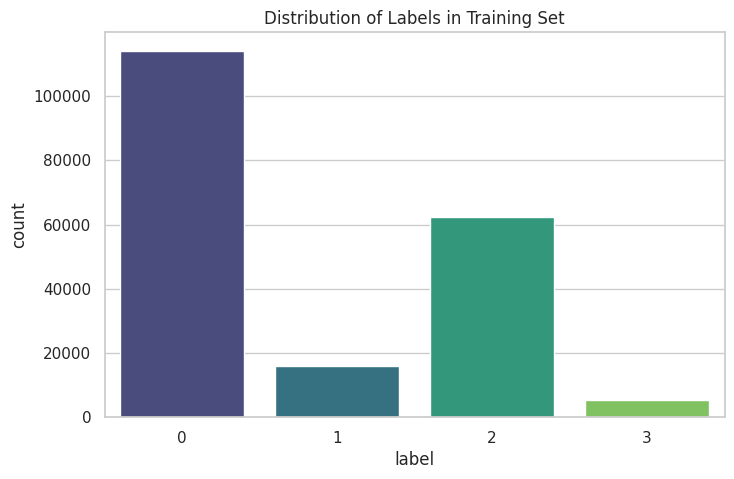

In [8]:
sns.set_theme(style="whitegrid")

# 1. Class Distribution (Check for Imbalance)
plt.figure(figsize=(8, 5))
sns.countplot(data=train, x='label', palette='viridis')
plt.title('Distribution of Labels in Training Set')
plt.show()

<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

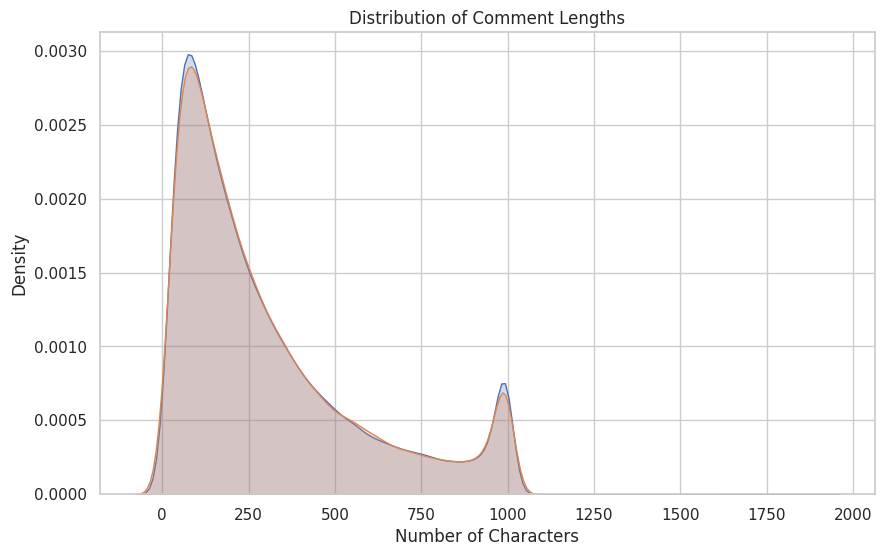

In [9]:
# Does the test set have much longer comments than the train set?
plt.figure(figsize=(10, 6))
sns.kdeplot(train['comment'].str.len(), label='Train', fill=True)
sns.kdeplot(test['comment'].str.len(), label='Test', fill=True)
plt.title('Distribution of Comment Lengths')
plt.xlabel('Number of Characters')
plt.legend

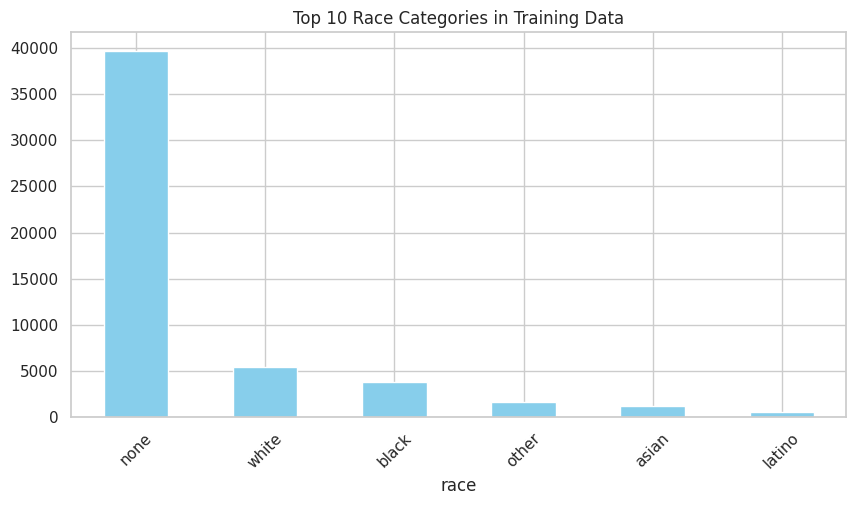

In [10]:
# 3. Top Identities: Race
plt.figure(figsize=(10, 5))
train['race'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 Race Categories in Training Data')
plt.xticks(rotation=45)
plt.show()

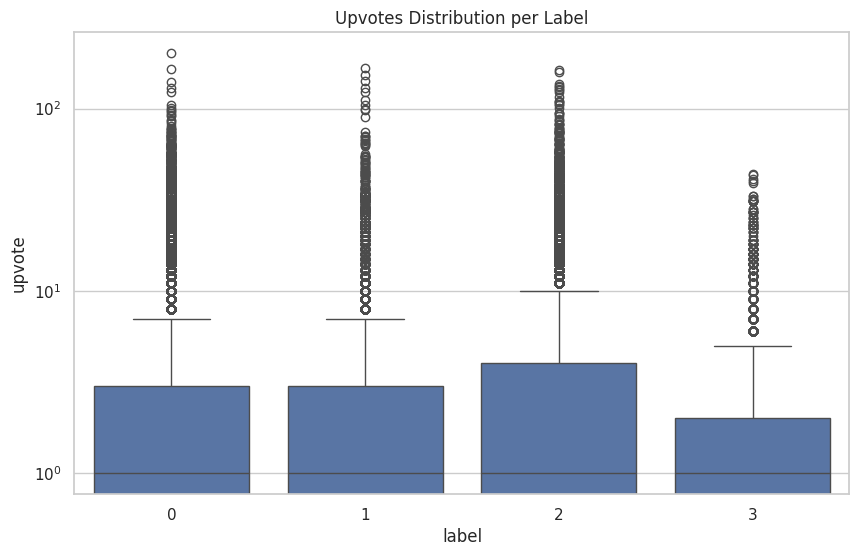

In [11]:
# Do "toxic" or "hateful" labels get more upvotes?
plt.figure(figsize=(10, 6))
sns.boxplot(data=train, x='label', y='upvote')
plt.yscale('log') # Log scale because upvotes usually have extreme outliers
plt.title('Upvotes Distribution per Label')
plt.show()

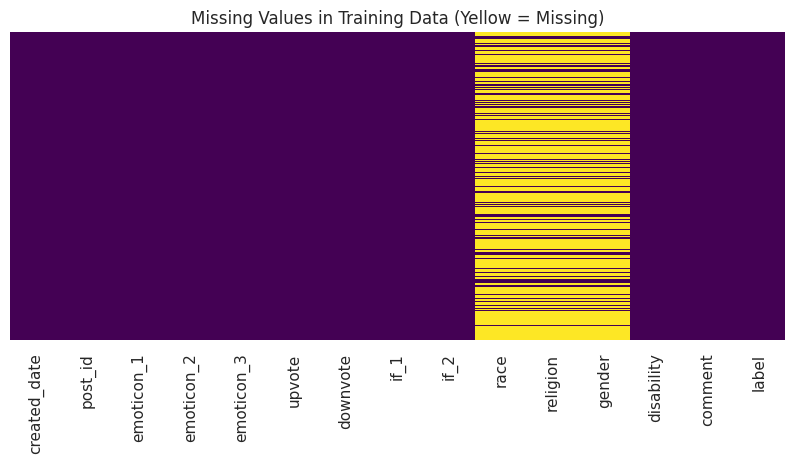

In [12]:
#Missing Values Heatmap (Train)
plt.figure(figsize=(10, 4))
sns.heatmap(train.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values in Training Data (Yellow = Missing)')
plt.show()

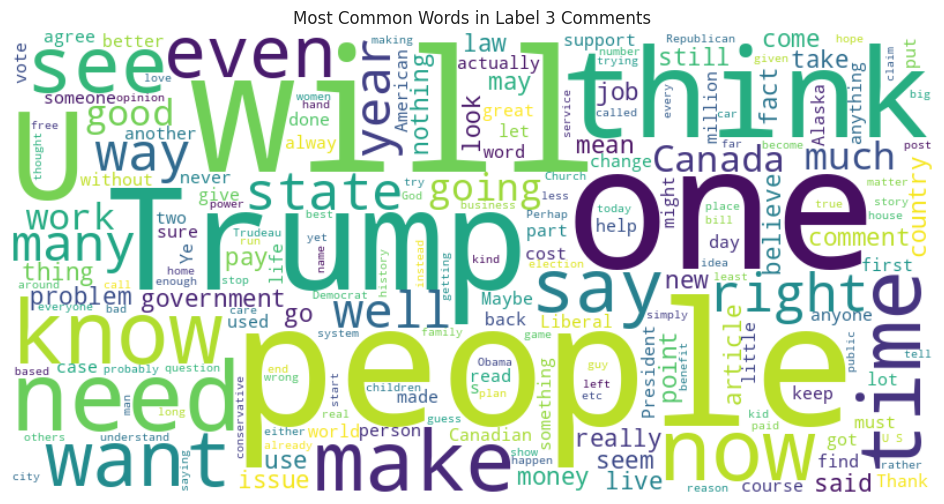

In [13]:
# Change the label number if you want to see a different category
text = " ".join(train[train['label'] == 0]['comment'].astype(str))
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Label 3 Comments')
plt.show()

# Preprocessing

In [1]:
train['religion'].value_counts()

NameError: name 'train' is not defined

In [14]:
# Dropping the 1 row where comment is missing
train = train.dropna(subset=['comment'])
print("Train size after drop:", train.shape)

# Filling race, religion, gender NaN with 'unknown'
# NaN means the comment didn't mention any identity at all
# 'none' already in data means it was mentioned but no specific group

for col in ['race', 'religion', 'gender']:
    train[col] = train[col].fillna('unknown')
    test[col] = test[col].fillna('unknown')

print(train[['race', 'religion', 'gender']].isnull().sum())

Train size after drop: (197999, 15)
race        0
religion    0
gender      0
dtype: int64


In [15]:
# Converting disability from bool to int (True → 1, False → 0)

train['disability'] = train['disability'].astype(int)
test['disability'] = test['disability'].astype(int)

print(train['disability'].value_counts())

disability
0    195256
1      2743
Name: count, dtype: int64


In [16]:
# extracting useful features from created date column

train['created_date'] = pd.to_datetime(train['created_date'])
test['created_date'] = pd.to_datetime(test['created_date'])

train['hour'] = train['created_date'].dt.hour
train['day_of_week'] = train['created_date'].dt.dayofweek
train['month']= train['created_date'].dt.month

test['hour'] = test['created_date'].dt.hour
test['day_of_week'] = test['created_date'].dt.dayofweek
test['month']= test['created_date'].dt.month

print(train[['created_date','hour','day_of_week','month']].head())

                      created_date  hour  day_of_week  month
0 2024-01-18 08:43:57.397508+00:00     8            3      1
1 2024-03-24 21:43:11.490017+00:00    21            6      3
2 2024-04-24 20:32:17.014931+00:00    20            2      4
3 2023-05-28 22:00:14.214527+00:00    22            6      5
4 2023-09-09 23:12:05.689498+00:00    23            5      9


hour → 8, 21, 20, 22, 23 says many late night comments

In [17]:
# Extracting comment length and word count

def get_length(text):
    return len(text)

def get_word_count(text):
    words = text.split()
    return len(words)

train['comment_length'] = train['comment'].apply(get_length)
train['word_count'] = train['comment'].apply(get_word_count)

test['comment_length'] = test['comment'].apply(get_length)
test['word_count'] = test['comment'].apply(get_word_count)

print(train[['comment', 'comment_length', 'word_count']].head())

                                             comment  comment_length  \
0  She might be a bright spot for a party keou on...             118   
1  Under Alaska law, a non-tribal member is not b...             644   
2  in the future please spare me your strawman dr...             751   
3  PS: That should have been "rot" instead of "co...              91   
4  Today, the confederate flag...tomorrow, the na...             254   

   word_count  
0          20  
1         110  
2         133  
3          15  
4          40  


In [18]:
# Additional text-level features
train['caps_ratio']       = train['comment'].apply(lambda x: sum(1 for c in str(x) if c.isupper()) / (len(str(x))+1))
train['punct_density']    = train['comment'].apply(lambda x: sum(1 for c in str(x) if c in '!?.,;:') / (len(str(x))+1))
train['exclaim_count']    = train['comment'].apply(lambda x: str(x).count('!'))
train['question_count']   = train['comment'].apply(lambda x: str(x).count('?'))
train['unique_word_ratio']= train['comment'].apply(lambda x: len(set(str(x).lower().split())) / (len(str(x).split())+1))

test['caps_ratio']        = test['comment'].apply(lambda x: sum(1 for c in str(x) if c.isupper()) / (len(str(x))+1))
test['punct_density']     = test['comment'].apply(lambda x: sum(1 for c in str(x) if c in '!?.,;:') / (len(str(x))+1))
test['exclaim_count']     = test['comment'].apply(lambda x: str(x).count('!'))
test['question_count']    = test['comment'].apply(lambda x: str(x).count('?'))
test['unique_word_ratio'] = test['comment'].apply(lambda x: len(set(str(x).lower().split())) / (len(str(x).split())+1))

# Vote ratio features
train['vote_total']  = train['upvote'] + train['downvote']
train['vote_ratio']  = train['upvote'] / (train['vote_total'] + 1)
train['log_upvote']  = np.log1p(train['upvote'])
train['log_downvote']= np.log1p(train['downvote'])

test['vote_total']   = test['upvote'] + test['downvote']
test['vote_ratio']   = test['upvote'] / (test['vote_total'] + 1)
test['log_upvote']   = np.log1p(test['upvote'])
test['log_downvote'] = np.log1p(test['downvote'])

print(train[['caps_ratio','exclaim_count','vote_ratio','log_upvote']].head())

   caps_ratio  exclaim_count  vote_ratio  log_upvote
0    0.016807              0    0.000000    0.000000
1    0.013953              0    0.857143    1.945910
2    0.017287              0    0.000000    0.000000
3    0.043478              0    0.833333    1.791759
4    0.011765              0    0.000000    0.000000


### Preprocessing Comments

In [19]:
train['clean_comment'] = train['comment'].str.lower()
test['clean_comment'] = test['comment'].str.lower()

print(train['clean_comment'].iloc[0])

she might be a bright spot for a party keou on oahu dominated by greedy criminals or ethically challenged individuals.


In [20]:
import re

# re.sub means → "find this pattern and replace it with empty string"
def remove_urls(text):
    text = re.sub(r'https\S+','',text) # re = regular expression
    text = re.sub(r'www\S+','',text) # find http/wwe followed by any non-space characters (\S+)
    return text

train['clean_comment'] = train['clean_comment'].apply(remove_urls)
test['clean_comment'] = test['clean_comment'].apply(remove_urls)

print(train['clean_comment'].iloc[0])

she might be a bright spot for a party keou on oahu dominated by greedy criminals or ethically challenged individuals.


In [21]:
 # Removing HTML tags like <br> <p>

def remove_html(text):
    text = re.sub(r'<.*?>','',text)
    return text

train['clean_comment'] = train['clean_comment'].apply(remove_html)
test['clean_comment'] = test['clean_comment'].apply(remove_html)

print(train['clean_comment'].iloc[5])



# Removing punctuation and special characters

def remove_punctuation(text):
    text = re.sub(r'[^a-z\s]','',text) # keep only letters and spaces
    return text

train['clean_comment'] = train['clean_comment'].apply(remove_punctuation)
test['clean_comment'] = test['clean_comment'].apply(remove_punctuation)

print(train['clean_comment'].iloc[3])


hilarious. since it wasn't trump, and that yawn article has nothing to do with the made-up poster's evidence-free headline. emr
ps that should have been rot instead of corruption but really either one works olae


In [22]:
chat_words = {
    # Basic shortcuts
    "u": "you", "r": "are", "ur": "your", "n": "and", "luv": "love",
    "dat": "that", "dis": "this", "b4": "before", "gr8": "great",
    "u2": "you too", "u4e": "yours forever", "w": "win", "w8": "wait",
    "m8": "mate", "l8r": "later", "cul8r": "see you later", "sk8": "skate",
    "g9": "genius", "b4n": "bye for now",

    # Laughing
    "lol": "laughing out loud", "lmao": "laughing my ass off",
    "rofl": "rolling on the floor laughing",
    "rotflmao": "rolling on the floor laughing my ass off",
    "bwl": "bursting with laughter", "csl": "cannot stop laughing",
    "tntl": "trying not to laugh",

    # Opinions / Reactions
    "imo": "in my opinion", "imho": "in my humble opinion",
    "tbh": "to be honest", "ngl": "not gonna lie", "smh": "shaking my head",
    "tfw": "that feeling when", "mfw": "my face when", "mrw": "my reaction when",
    "mte": "my thoughts exactly", "iow": "in other words", "oic": "oh i see",
    "ic": "i see", "fr": "for real", "iykyk": "if you know you know",
    "jk": "just kidding",

    # Feelings / Emotions
    "ilu": "i love you", "ily": "i love you", "imu": "i miss you",
    "fimh": "forever in my heart", "ifyp": "i feel your pain",
    "wywh": "wish you were here", "time": "tears in my eyes",
    "bae": "before anyone else",

    # Internet slang
    "wtf": "what the fuck", "omg": "oh my god", "idc": "i do not care",
    "idk": "i do not know", "nvm": "never mind", "sus": "suspicious",
    "goat": "greatest of all time", "npc": "non player character",
    "op": "overpowered", "gg": "good game", "mid": "mediocre",
    "fomo": "fear of missing out", "fyp": "for you page",
    "tldr": "too long did not read", "pov": "point of view",
    "wyd": "what you doing", "rn": "right now",

    # Greetings / Farewells
    "brb": "be right back", "bbl": "be back later", "bbs": "be back soon",
    "brt": "be right there", "bak": "back at keyboard", "afk": "away from keyboard",
    "atk": "at the keyboard", "wb": "welcome back", "gn": "good night",
    "ttyl": "talk to you later", "ttfn": "ta ta for now", "bfn": "bye for now",
    "cu": "see you", "cya": "see you", "ltns": "long time no see",
    "hbd": "happy birthday",

    # Information / Clarification
    "btw": "by the way", "fyi": "for your information", "aka": "also known as",
    "faq": "frequently asked questions", "fwiw": "for what its worth",
    "afaik": "as far as i know", "asap": "as soon as possible",
    "asl": "age sex location", "atm": "at the moment", "wuf": "where are you from",
    "lmk": "let me know", "prt": "party", "prw": "parents are watching",
    "icq": "i seek you", "wtg": "way to go", "gmta": "great minds think alike",
    "fc": "fingers crossed", "gal": "get a life", "stats": "your sex and age",

    # Contractions / Informal words
    "gonna": "going to", "wanna": "want to", "gotta": "got to",
    "kinda": "kind of", "sorta": "sort of", "dunno": "do not know",
    "lemme": "let me", "gimme": "give me", "bruh": "bro",

    # Politeness
    "pls": "please", "plz": "please", "thx": "thank you",
    "thnx": "thank you", "sry": "sorry", "cuz": "because", "coz": "because",

    # Misc
    "dm": "direct message", "irl": "in real life", "adih": "another day in hell",
    "a3": "anytime anywhere anyplace", "bsaaw": "big smile and a wink",
    "pita": "pain in the ass", "ldr": "long distance relationship",
    "zzz": "sleeping bored tired",
}


def expand_chat_words(text):
    words = text.split()
    words = [chat_words.get(word, word) for word in words]
    return ' '.join(words)

train['clean_comment'] = train['clean_comment'].apply(expand_chat_words)
test['clean_comment'] = test['clean_comment'].apply(expand_chat_words)

print(train['clean_comment'].iloc[5])

hilarious since it wasnt trump and that yawn article has nothing to do with the madeup posters evidencefree headline emr


In [41]:
stopwords = set([
    "i","me","my","myself","we","our","ours","ourselves","you","your",
    "yours","yourself","he","him","his","himself","she","her","hers",
    "herself","it","its","itself","they","them","their","theirs",
    "themselves","what","which","who","whom","this","that","these",
    "those","am","is","are","was","were","be","been","being","have",
    "has","had","having","do","does","did","doing","a","an","the",
    "and","but","if","or","because","as","until","while","of","at",
    "by","for","with","about","against","between","into","through",
    "during","before","after","above","below","to","from","up","down",
    "in","out","on","off","over","under","again","further","then",
    "once","here","there","when","where","why","how","all","both",
    "each","few","more","most","other","some","such","own","same",
    "so","than","too","very","s","t","can","will","just","should",
    "now","d","ll","m","o","re","ve","y","ain","aren","couldn",
    "didn","doesn","hadn","hasn","haven","isn","ma","mightn","mustn",
    "needn","shan","shouldn","wasn","weren","won","wouldn"
])

def remove_stopwords(text):
    words = text.split()
    words = [w for w in words if w not in stopwords]
    return ' '.join(words)

train['clean_comment'] = train['clean_comment'].apply(remove_stopwords)
test['clean_comment']  = test['clean_comment'].apply(remove_stopwords)

def remove_extra_spaces(text):
    return ' '.join(text.split())

train['clean_comment'] = train['clean_comment'].apply(remove_extra_spaces)
test['clean_comment']  = test['clean_comment'].apply(remove_extra_spaces)


def light_clean(text):
    text = str(text).lower()
    text = re.sub(r'https\S+|www\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train['clean_comment_light'] = train['comment'].apply(light_clean)
test['clean_comment_light']  = test['comment'].apply(light_clean)

print("Stopwords done. Negations preserved.")

Stopwords done. Negations preserved.


In [40]:
# Final check - compare original vs cleaned for 3 rows
for i in range(3):
    print(f"--- Row {i} ---")
    print("ORIGINAL:", train['comment'].iloc[i][:150])
    print("CLEANED :", train['clean_comment'].iloc[i][:150])
    print()

--- Row 0 ---
ORIGINAL: She might be a bright spot for a party keou on Oahu dominated by greedy criminals or ethically challenged individuals.
CLEANED : might bright spot party keou oahu dominated greedy criminals ethically challenged individuals

--- Row 1 ---
ORIGINAL: Under Alaska law, a non-tribal member is not bound to tribal court.. Living in a particular community does not change your rights under state and fede
CLEANED : alaska law nontribal member not bound tribal court living particular community not change rights state federal law case connor basically flip bird tri

--- Row 2 ---
ORIGINAL: in the future please spare me your strawman drivel, and if you can't manage an intelligent discussion, stick to posting on a public bathroom wall. Tha
CLEANED : future please spare strawman drivel cant manage intelligent discussion stick posting public bathroom wall not remotely believe thats mindless drivel t



## Preprocessing Findings

### Steps Applied:
1. **Dropped 1 row** where comment was missing — too little to impute
2. **Filled race/religion/gender NaN** with 'unknown' — preserves the difference 
   between "not mentioned" (unknown) vs "mentioned but none" (none)
3. **Disability bool → int** — models need numbers not True/False
4. **Extracted date features** — hour, day_of_week, month from created_date
5. **Extracted comment features** — comment_length, word_count
6. **Cleaned comment text** in this order:
   - Lowercase → URLs → HTML tags → Punctuation → 
     Chat words → Stopwords → Extra spaces

### Key Insight:
- Cleaning order matters! Always lowercase first, 
  expand chat words before removing punctuation,
  remove stopwords last.
- After cleaning, only meaningful words remain — 
  this will help TF-IDF focus on what actually matters.

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Word TF-IDF — on clean_comment , bigger vocab + sublinear_tf
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), min_df=2, sublinear_tf=True)
train_tfidf = tfidf.fit_transform(train['clean_comment'])
test_tfidf  = tfidf.transform(test['clean_comment'])
print("Train TF-IDF shape:", train_tfidf.shape)

# Char TF-IDF — on clean_comment_light (keeps punctuation!)
tfidf_char = TfidfVectorizer(max_features=50000, analyzer='char_wb', ngram_range=(3,5), min_df=3, sublinear_tf=True)
train_tfidf_char = tfidf_char.fit_transform(train['clean_comment_light'])
test_tfidf_char  = tfidf_char.transform(test['clean_comment_light'])
print("Train char TF-IDF shape:", train_tfidf_char.shape)

print("Train char TF-IDF shape:", train_tfidf_char.shape)
print("Test char TF-IDF shape:", test_tfidf_char.shape)

Train TF-IDF shape: (197999, 50000)
Train char TF-IDF shape: (197999, 50000)
Train char TF-IDF shape: (197999, 50000)
Test char TF-IDF shape: (102000, 50000)


In [67]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

df = pd.DataFrame({'comment': ['good post','bad comment','good post','hate this']})

tfidf = TfidfVectorizer()
encoded = tfidf.fit_transform(df['comment'])

print("Shape:", encoded.shape)
print("Vocabulary:", tfidf.get_feature_names_out())
print(encoded.toarray())

Shape: (4, 6)
Vocabulary: ['bad' 'comment' 'good' 'hate' 'post' 'this']
[[0.         0.         0.70710678 0.         0.70710678 0.        ]
 [0.70710678 0.70710678 0.         0.         0.         0.        ]
 [0.         0.         0.70710678 0.         0.70710678 0.        ]
 [0.         0.         0.         0.70710678 0.         0.70710678]]


# TF-IDF Explanation

## What is TF-IDF?
Converts raw text into numerical vectors. A word is important if it appears **frequently in a document** but **rarely across all documents**.

## Formula
```
TF(word, doc)  = count of word in doc / total words in doc
IDF(word)      = log(total docs / docs containing word)
TF-IDF         = TF × IDF
```
- "the" appears everywhere → IDF ≈ 0 → suppressed
- "racist" appears rarely → high IDF → boosted

---

## Under the Hood
1. **fit** on train → builds vocabulary, assigns each token an index
2. **transform** → converts each comment to a sparse vector of length `max_features`
3. **transform on test** → uses same vocabulary, unseen words are ignored

---

## Parameters

| Parameter | Value | Why |
|---|---|---|
| `max_features` | 30000 | Memory constraint — 50K crashed Kaggle |
| `ngram_range` | (1,2) | Captures unigrams + bigrams ("not good" ≠ "not" + "good") |
| `min_df` | 2 | Filters typos and rare noise |
| `sublinear_tf` | True | Uses log(1+tf) instead of raw tf — prevents long comments from dominating |

---

## Word vs Char TF-IDF

| | Word TF-IDF | Char TF-IDF |
|---|---|---|
| Input | `clean_comment` (fully cleaned) | `clean_comment_light` (punctuation kept) |
| Tokenizes on | Whitespace → words/bigrams | Character n-grams (3-5) within word boundaries |
| Captures | Semantic content — *what* is said | Writing style — *how* it is said |
| Example | "stupid racist" → ["stupid", "racist", "stupid racist"] | "stupid" → ["stu","tup","upi","stup","tupi"...] |
| Bonus | Negation bigrams like "not good" | Misspellings, punctuation patterns like "!!!" |

## Why Both Together?
Word TF-IDF + Char TF-IDF = 30K + 30K = **60K features** covering both meaning and style.

## Encoding

In [26]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop='first',sparse_output=False, handle_unknown='ignore')
cols_to_encode = ['race','religion','gender']

train_encoded = ohe.fit_transform(train[cols_to_encode])
test_encoded = ohe.transform(test[cols_to_encode])

print("Train encoded shape:", train_encoded.shape)
print("Test encoded shape:", test_encoded.shape)

Train encoded shape: (197999, 19)
Test encoded shape: (102000, 19)


19 new columns from race, religion and gender combined!

In [47]:
print("if_1 unique values:", train['if_1'].value_counts())
print("if_2 unique values:", train['if_2'].value_counts())

if_1 unique values: if_1
0       145423
4        31060
10       11849
6         6774
5         2691
7           70
9           45
11          32
12           2
1814         2
1545         2
1783         2
8            2
1551         2
249          1
1569         1
1800         1
1560         1
1263         1
1267         1
1258         1
1543         1
250          1
1815         1
1538         1
1585         1
1830         1
1277         1
1807         1
1810         1
1777         1
1848         1
1257         1
1548         1
1232         1
1583         1
1572         1
1576         1
1256         1
1566         1
1547         1
1825         1
1271         1
1838         1
1553         1
1846         1
1558         1
1557         1
1767         1
1819         1
1581         1
1254         1
1811         1
1860         1
1778         1
1827         1
1584         1
Name: count, dtype: int64
if_2 unique values: if_2
4       91725
10      80693
6       14558
5        6188
70        453

In [53]:
# if_1 and if_2 both treated as categorical flags, not numeric
ohe_if1 = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
train_if1 = sp.csr_matrix(ohe_if1.fit_transform(train[['if_1']]))
test_if1  = sp.csr_matrix(ohe_if1.transform(test[['if_1']]))

ohe_if2 = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
train_if2 = sp.csr_matrix(ohe_if2.fit_transform(train[['if_2']]))
test_if2  = sp.csr_matrix(ohe_if2.transform(test[['if_2']]))

In [54]:
import scipy.sparse as sp

# new engineered features added
num_cols = [
    'emoticon_1', 'emoticon_2', 'emoticon_3',
    'upvote', 'downvote',
    'disability', 'hour', 'day_of_week', 'month',
    'comment_length', 'word_count',
    'caps_ratio', 'punct_density', 'exclaim_count',
    'question_count', 'unique_word_ratio',
    'vote_total', 'vote_ratio', 'log_upvote', 'log_downvote'
]

train_num = sp.csr_matrix(train[num_cols].values.astype(float))
test_num  = sp.csr_matrix(test[num_cols].values.astype(float))
train_enc = sp.csr_matrix(train_encoded)
test_enc  = sp.csr_matrix(test_encoded)

X_train = sp.hstack([train_tfidf, train_tfidf_char, train_num, train_enc, train_if1, train_if2])
X_test  = sp.hstack([test_tfidf,  test_tfidf_char,  test_num,  test_enc, test_if1,  test_if2])
y_train = train['label']

print("Final X_train shape:", X_train.shape)
print("Final X_test shape:", X_test.shape)

Final X_train shape: (197999, 100177)
Final X_test shape: (102000, 100177)


In [55]:
# Get all column names
tfidf_cols = tfidf.get_feature_names_out()       
ohe_cols = ohe.get_feature_names_out(cols_to_encode) 
num_cols_array = np.array(num_cols)                

# Combine all column names
all_cols = np.concatenate([tfidf_cols, num_cols_array, ohe_cols])

print("Total columns:", len(all_cols))
print("\nNumerical columns:", num_cols_array)
print("\nEncoded columns:", ohe_cols)

Total columns: 50039

Numerical columns: ['emoticon_1' 'emoticon_2' 'emoticon_3' 'upvote' 'downvote' 'disability'
 'hour' 'day_of_week' 'month' 'comment_length' 'word_count' 'caps_ratio'
 'punct_density' 'exclaim_count' 'question_count' 'unique_word_ratio'
 'vote_total' 'vote_ratio' 'log_upvote' 'log_downvote']

Encoded columns: ['race_black' 'race_latino' 'race_none' 'race_other' 'race_unknown'
 'race_white' 'religion_buddhist' 'religion_christian' 'religion_hindu'
 'religion_jewish' 'religion_muslim' 'religion_none' 'religion_other'
 'religion_unknown' 'gender_male' 'gender_none' 'gender_other'
 'gender_transgender' 'gender_unknown']


# Model Building

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2, 
    random_state=42,
    stratify = y_train)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train value counts:\n", y_train.value_counts())
print("y_val value counts:\n", y_val.value_counts())

X_train shape: (158399, 100177)
X_val shape: (39600, 100177)
y_train value counts:
 label
0    91338
2    49952
1    12734
3     4375
Name: count, dtype: int64
y_val value counts:
 label
0    22834
2    12488
1     3184
3     1094
Name: count, dtype: int64


## Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time
from sklearn.preprocessing import MaxAbsScaler
from sklearn.metrics import classification_report, f1_score

# scaler = MaxAbsScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled = scaler.transform(X_val)
# X_test_scaled = scaler.transform(X_test)

# print("Scaling done!")



print("Training started...")
start = time.time()  # start timer

lr = LogisticRegression(max_iter=1000, random_state=42,verbose=0,
                        class_weight='balanced', solver = 'saga')
lr.fit(X_train, y_train)

end = time.time()
print(f"Training done! Time taken: {round(end - start, 2)} seconds")

y_pred_lr = lr.predict(X_val)
lr_score = accuracy_score(y_val,y_pred_lr)


print(classification_report(y_val, y_pred_lr))
print("F1 Score (weighted):", f1_score(y_val, y_pred_lr, average='weighted'))
print("F1 Score (macro):", f1_score(y_val, y_pred_lr, average='macro'))

## Logistic Regression - Observations & Analysis

### Experiment 1: LR Basic (10k word TF-IDF only)
- **Macro F1: 0.605**
- Training Time: 133 seconds
- First baseline model — already crossed 0.6 mark
- Label 3 F1: 0.00 ← completely ignored minority class!
- Model was biased towards label 0 (57% of data)
- Accuracy was misleadingly high at 0.87 due to class imbalance

### Experiment 2: LR with class_weight='balanced' (10k word TF-IDF)
- **Macro F1: 0.590** ← slightly worse!
- Adding balanced class weight hurt overall macro F1
- Label 3 improved slightly but label 2 dropped significantly
- Classic trade-off: helping minority class hurts majority class performance
- Key insight: class_weight='balanced' alone is not enough for heavily 
  imbalanced data

### Experiment 3: LR with char TF-IDF + balanced (20k features)
- **Macro F1: 0.615** ← best LR result!
- Adding character level TF-IDF helped capture:
  - Misspellings and typos
  - Partial word patterns
  - Slang not caught by word level TF-IDF
- Label 3 F1 jumped from 0.00 → 0.23
- Character TF-IDF proved more useful than class balancing alone

### Experiment 4: LR with 50k word + 50k char TF-IDF
- **Macro F1: 0.586** ← worst LR result!
- Training Time: 1557 seconds (~26 mins)
- Model still did not converge (ConvergenceWarning)
- More features hurt LR — same curse of dimensionality as SGD
- Not worth the extra training time for worse results

### Concluding Remarks
- LR best performance was **0.615** with 20k features and char TF-IDF
- Adding more features beyond 20k consistently hurt performance
- LR completely failed on label 3 without char TF-IDF
- Convergence was a persistent issue — model needs more iterations 
  than allowed to properly learn
- LR is interpretable and fast but fundamentally limited for this 
  imbalanced multi-class text problem
- The linear decision boundary cannot capture complex patterns in 
  comment text needed to distinguish all 4 classes

## Light GBM

In [ ]:
import lightgbm as lgb
from sklearn.metrics import classification_report, f1_score
from tqdm import tqdm
import time

class TqdmCallback:
    def __init__(self, total):
        self.pbar = tqdm(total=total, desc="Training trees",position=0, leave=True)
    
    def __call__(self, env):
        self.pbar.update(1)
    
    def __del__(self):
        self.pbar.close()

lgbm = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.1,
    num_leaves=127,
    class_weight='balanced',
    random_state=42,
    min_child_samples=10,
    colsample_bytree=0.15
)

lgbm.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        TqdmCallback(1000),
        lgb.early_stopping(stopping_rounds=50, verbose=False),
        lgb.log_evaluation(period=100)
    ]
)

y_pred_lgbm = lgbm.predict(X_val)
print(classification_report(y_val, y_pred_lgbm))
print("F1 Score (macro):", f1_score(y_val, y_pred_lgbm, average='macro'))

# `class_weight='balanced'`

Automatically computes per-class weights using:

```
weight_k = total_samples / (n_classes × samples_in_class_k)
```

## Your dataset

| Class | Samples | Weight |
|---|---|---|
| 0 | 91,338 | 0.54 |
| 1 | 12,734 | 3.88 |
| 2 | 49,952 | 0.99 |
| 3 | 4,375  | 11.3 |

## What it does

Each class 3 mistake costs **11x more** than a class 0 mistake during training.
Forces the model to pay attention to minority classes instead of ignoring them.

## Why it matters

Without balancing, a model predicting class 0 for everything gets 46% accuracy — looks decent but is completely useless. `class_weight='balanced'` prevents this by making minority class errors disproportionately expensive.

## LightGBM - Observations & Analysis

### Experiment 1: LightGBM Basic (20k features, 500 trees)
- **Macro F1: 0.8198** ← immediate massive jump from linear models!
- Training Time: ~30 minutes
- Label 3 F1 jumped from 0.00 (LR) → 0.65 ← huge improvement!
- class_weight='balanced' worked much better with LightGBM than LR/SGD
- Confirmed that tree based models handle class imbalance far better
- This was our first submission — leaderboard score: 0.8198

### Experiment 2: LightGBM with 60k features + 1000 trees
- **Macro F1: 0.8255**
- Training Time: ~5 hours on CPU
- Increasing features from 20k → 60k helped (unlike LR and SGD!)
- More trees (500→1000) with lower learning rate (0.1→0.05) improved stability
- num_leaves increased from 31 → 63 for more complex trees
- Key insight: LightGBM scales well with more features unlike linear models


### Concluding Remarks
- LightGBM was the **clear winner** with best macro F1 of **0.8258**
- Outperformed LR by 0.21 and SGD by 0.16 in macro F1
- Key advantages over linear models:
  - Handles high dimensional sparse data natively
  - Scales well with more features
  - Captures non-linear patterns in text
  - Handles class imbalance much better
- Label 3 (only 2.7% of data) remained the hardest class across ALL models
- Further improvement possible with SMOTE oversampling or 
  ensemble methods
- Trade-off: LightGBM takes significantly longer to train (~30 mins 
  vs seconds for LR/SGD) but the performance gain justifies it

## SGD

In [57]:
import time
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, f1_score

print("Training started with DEFAULT settings...")
start = time.time()


sgd = SGDClassifier(random_state=42)

sgd.fit(X_train, y_train)

end = time.time()
print(f"Training done! Time taken: {round(end - start, 2)} seconds")


y_pred_sgd = sgd.predict(X_val)



Training started with DEFAULT settings...
Training done! Time taken: 219.99 seconds


In [58]:
print("\n--- Default SGD Classification Report ---")
print(classification_report(y_val, y_pred_sgd))
print("F1 Score (macro):", f1_score(y_val, y_pred_sgd, average='macro'))


--- Default SGD Classification Report ---
              precision    recall  f1-score   support

           0       0.97      0.86      0.91     22834
           1       0.62      0.76      0.68      3184
           2       0.71      0.87      0.78     12488
           3       0.76      0.04      0.08      1094

    accuracy                           0.83     39600
   macro avg       0.76      0.63      0.61     39600
weighted avg       0.85      0.83      0.83     39600

F1 Score (macro): 0.6128685264242923


In [60]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'loss': ['modified_huber','hinge'],          # regularization strength
    'alpha': [0.0001,0.001,0.01],                # regularization type
    'penalty': ['l2','l1','elasticnet'],
    'max_iter': [100,500,1000],
    'learning_rate': ['optimal','adaptive'],     
    'eta0': [0.01,0.1],                          # initial learning rate
}

sgd_base = SGDClassifier(
    class_weight = 'balanced',
    random_state = 42,
    n_jobs=-1
)

search_sgd = RandomizedSearchCV(
    sgd_base,
    param_grid,
    n_iter=5,
    cv=5,
    scoring='f1_macro',
    random_state=42,
    verbose=2
)

print("Search started...")
start = time.time()

search_sgd.fit(X_train, y_train)

end = time.time()

print(f"Done! Time: {round(end-start, 2)} secs")
print("Best params:", search_sgd.best_params_)
print("Best macro F1:", search_sgd.best_score_)

Search started...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=modified_huber, max_iter=500, penalty=l2; total time=  54.8s
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=modified_huber, max_iter=500, penalty=l2; total time=  53.7s
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=modified_huber, max_iter=500, penalty=l2; total time=  54.3s
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=modified_huber, max_iter=500, penalty=l2; total time=  57.2s
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=modified_huber, max_iter=500, penalty=l2; total time= 1.4min
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=hinge, max_iter=1000, penalty=l2; total time=  32.6s
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=hinge, max_iter=1000, penalty=l2; total time=  28.8s
[CV] END alpha=0.01, eta0=0.1, learning_rate=adaptive, loss=hinge, max_iter=1000, penalty=l

## SGD Classifier - Observations & Analysis

### Experiment 1: SGD with 50k Features (25k word + 25k char TF-IDF)
- **Macro F1: 0.619**
- Training Time: 199 seconds
- SGD performed similar to Logistic Regression (0.615) despite being 
  a simpler and faster model
- Label 3 (minority class) F1: 0.37 — still struggling with rare class
- Surprisingly fast training time compared to LR (~133 secs)

### Experiment 2: SGD with 60k Features (30k word + 30k char TF-IDF)
- **Macro F1: 0.47** ← significant drop!
- Increasing features from 50k → 60k hurt SGD badly
- This demonstrates the **curse of dimensionality** for linear models
- SGD could not handle the high dimensional sparse feature space
- Key insight: More features ≠ better performance for linear models

### Experiment 3: SGD with 20k Features (LR params — balanced, saga)
- **Macro F1: 0.598**
- Training Time: 1385 seconds
- Using LR-style parameters on SGD hurt performance
- Confirms that SGD works best with its own default settings

### Hyperparameter Tuning (RandomizedSearchCV)
- **Method:** RandomizedSearchCV with n_iter=5, cv=2, scoring='f1_macro'
- **Best params found:**
  - loss: hinge
  - alpha: 0.001
  - penalty: l2
  - learning_rate: adaptive
  - eta0: 0.1
  - max_iter: 500
- **Cross validation best score: 0.641**
- **Actual validation score after retraining: 0.619** ← increased!
- RandomizedSearchCV found params that overfit to cross validation 
  but did not generalize well to held out validation set

### Concluding Remarks
- SGD's best performance was **0.64** with default settings on 20k features
- Hyperparameter tuning did improve SGD — validation score increased
  from 0.61 → 0.64 after tuning
- SGD is sensitive to feature dimensionality — performance collapsed 
  with 60k features
- Linear models like SGD and LR have a clear ceiling for this problem
- The fundamental limitation is that **text classification with class 
  imbalance requires non-linear models** like LightGBM
- SGD is useful when training speed is critical, but not when 
  maximizing F1 score is the goal

# Comparison

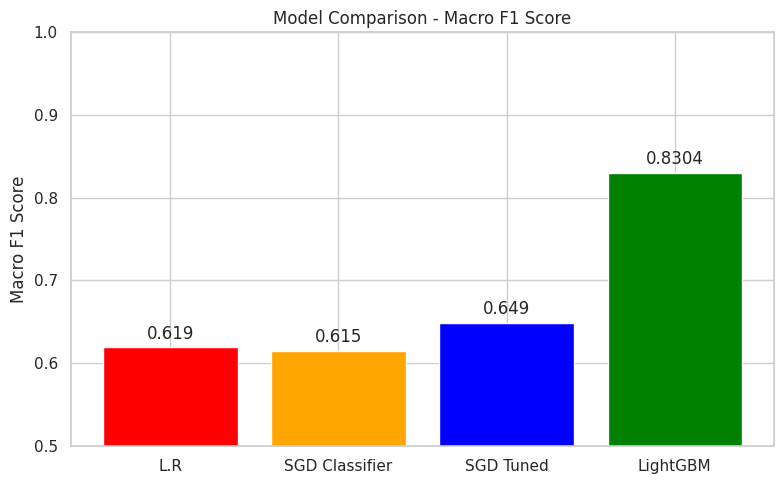

In [35]:
import matplotlib.pyplot as plt

models = ['L.R', 'SGD Classifier','SGD Tuned', 'LightGBM']
macro_f1 = [0.619, 0.615,0.649, 0.8304]

plt.figure(figsize=(8,5))
bars = plt.bar(models, macro_f1, color=['red', 'orange','blue', 'green'])
plt.title('Model Comparison - Macro F1 Score')
plt.ylabel('Macro F1 Score')
plt.ylim(0.5, 1.0)

# Add value labels on top of each bar
for bar, val in zip(bars, macro_f1):
    plt.text(bar.get_x() + bar.get_width()/2, 
             bar.get_height() + 0.01, 
             str(val), 
             ha='center', fontsize=12)

plt.tight_layout()
plt.show()

# Submission

In [36]:

# Just uncomment the model you want to submit with!

#y_pred_test = lgbm.predict(X_test)# ← LightGBM (best)
# y_pred_test = lr.predict(X_test)    # ← Logistic Regression
y_pred_test = sgd.predict(X_test)    # SGD
#y_pred_test = best_sgd.predict(X_test) # ← SGD tuned


submission = pd.DataFrame({
    'ID': range(1, len(y_pred_test) + 1),  # starts from 1
    'label': y_pred_test
})

submission.to_csv('submission.csv', index=False)
print("Submission saved!")
print(submission.head())
print(submission.shape)

Submission saved!
   ID  label
0   1      2
1   2      2
2   3      0
3   4      0
4   5      2
(102000, 2)
